In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


# Qiskit Superposition 03
Various state can be expressed at the same time by creating superposition.
In terms of n bits binary number, we can easily make n states by operating Hadamard to all the qubits.  

What if we want to make less than n states with n qubits?
That is no so simple, so my goal is to make an algorithm which enables us to make any kinds of superposition.

In [2]:
import numpy as np
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit_backend_config import IBMQ, execute, Aer
from qiskit.visualization import plot_histogram
import math

### 3 qubits superposition 8 states, normal and easy

{'010': 136, '000': 129, '001': 134, '101': 132, '100': 127, '011': 124, '111': 132, '110': 110}


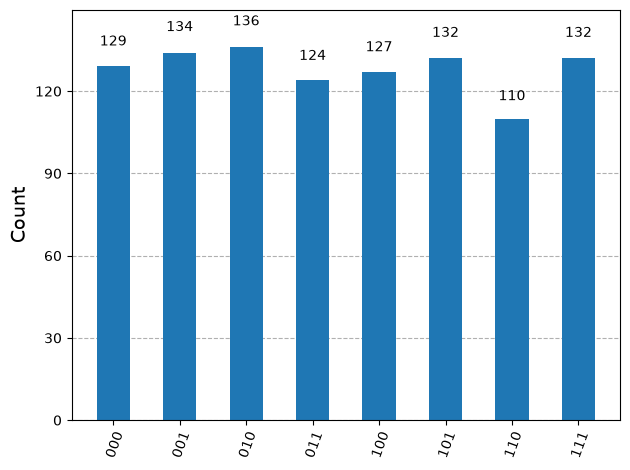

In [3]:
q = QuantumRegister(3, 'q')
c = ClassicalRegister(3, 'c')
qc = QuantumCircuit(q, c)

qc.h(q)

qc.measure(q[0:3], c[0:3])

r = execute(qc, Aer.get_backend('qasm_simulator')).result()
rc = r.get_counts()
print(rc)
plot_histogram(rc)

1. ry_arc
2. operate ch and break down the probability until all states' probability get equal

You also will be able to crete another 5 states superposition by operating x gates or  by changing the control qubit of ch gate.

In [4]:
def ry_arc(qubit, num):
    theta = 2 * np.arccos(1 / np.sqrt(num))
    qc.ry(theta, q[qubit])

{'101': 217, '011': 201, '000': 200, '111': 194, '001': 212}


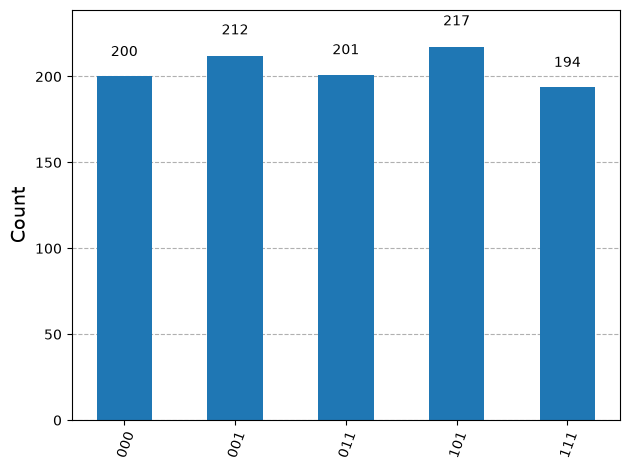

In [5]:
#000, 001, 011, 101, 111
q = QuantumRegister(3, 'q')
c = ClassicalRegister(3, 'c')
qc = QuantumCircuit(q, c)

ry_arc(0, 5)
qc.ch(q[0], q[1])
qc.ch(q[0], q[2])

qc.measure(q[0:3], c[0:3])

r = execute(qc, Aer.get_backend('qasm_simulator')).result()
rc = r.get_counts()
print(rc)
plot_histogram(rc)

{'101': 192, '111': 203, '001': 210, '010': 216, '011': 203}


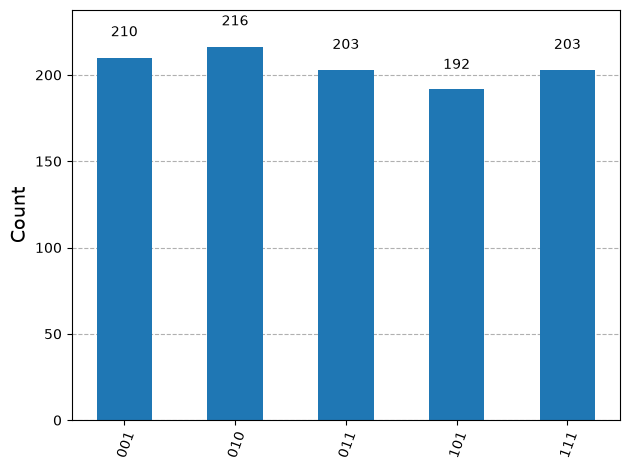

In [6]:
#001, 010, 011, 101, 111
q = QuantumRegister(3, 'q')
c = ClassicalRegister(3, 'c')
qc = QuantumCircuit(q, c)

ry_arc(0, 5)
qc.ch(q[0], q[1])
qc.ch(q[0], q[2])
qc.x(q[1])

qc.measure(q[0:3], c[0:3])

r = execute(qc, Aer.get_backend('qasm_simulator')).result()
rc = r.get_counts()
print(rc)
plot_histogram(rc)

{'010': 201, '110': 198, '100': 243, '000': 179, '111': 203}


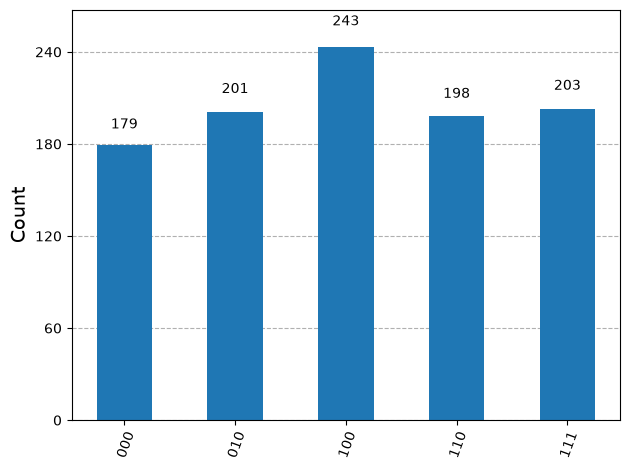

In [7]:
#000, 010, 100, 110, 111
q = QuantumRegister(3, 'q')
c = ClassicalRegister(3, 'c')
qc = QuantumCircuit(q, c)

ry_arc(0, 5)
qc.ch(q[0], q[1])
qc.ch(q[0], q[2])
qc.x(q[0:3])

qc.measure(q[0:3], c[0:3])

r = execute(qc, Aer.get_backend('qasm_simulator')).result()
rc = r.get_counts()
print(rc)
plot_histogram(rc)